# EDA For the Twibot dataset
Url: https://www.kaggle.com/datasets/goyaladi/twitter-bot-detection-dataset/data

Originally published in the paper "Unveiling Twitter Bot Detection: Analyzing Social Media Interactions", the Twibot dataset is a popular ML dataset, often used in the field of cyber security to create security classifiers.

In [48]:
import kagglehub
import pandas as pd
import numpy as numpy
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [11]:
dataset_path = 'goyaladi/twitter-bot-detection-dataset'

local_path = kagglehub.dataset_download("goyaladi/twitter-bot-detection-dataset")
df = pd.read_csv(local_path + "/bot_detection_data.csv")

df.head()

,User ID,Username,Tweet,Retweet Count,Mention Count,Follower Count,Verified,Bot Label,Location,Created At,Hashtags
0,132131,flong,Station activity person against natural majori...,85,1,2353,False,1,Adkinston,2020-05-11 15:29:50,NaN
1,289683,hinesstephanie,Authority research natural life material staff...,55,5,9617,True,0,Sanderston,2022-11-26 05:18:10,both live
2,779715,roberttran,Manage whose quickly especially foot none to g...,6,2,4363,True,0,Harrisonfurt,2022-08-08 03:16:54,phone ahead
3,696168,pmason,Just cover eight opportunity strong policy which.,54,5,2242,True,1,Martinezberg,2021-08-14 22:27:05,ever quickly new I
4,704441,noah87,Animal sign six data good or.,26,3,8438,False,1,Camachoville,2020-04-13 21:24:21,foreign mention


In [29]:
df.describe()

,User ID,Retweet Count,Mention Count,Follower Count,Bot Label,Created At,Hashtags Count
count,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000,50000.000000
mean,548890.680540,50.00560,2.513760,4988.602380,0.500360,2021-09-14 06:15:49.674620,2.500260
min,100025.000000,0.00000,0.000000,0.000000,0.000000,2020-01-01 00:44:14,0.000000
25%,323524.250000,25.00000,1.000000,2487.750000,0.000000,2020-11-03 09:24:48.500000,1.000000
50%,548147.000000,50.00000,3.000000,4991.500000,1.000000,2021-09-16 20:59:38,2.000000
75%,772983.000000,75.00000,4.000000,7471.000000,1.000000,2022-07-23 02:17:01.750000,4.000000
max,999995.000000,100.00000,5.000000,10000.000000,1.000000,2023-05-31 07:53:27,5.000000
std,259756.681425,29.18116,1.708563,2878.742898,0.500005,NaN,1.709368


## Bit of clean up 
Casting some of the features to the right type, ie time.

Also creates a new features "hashtags count", and "tweet leangth" for better dealing with hashtags

In [30]:
df['Created At'] = pd.to_datetime(df['Created At'], format='%Y-%m-%d %H:%M:%S')
df['Hashtags Count'] = df['Hashtags'].apply(lambda x: len(x.split(' ')) if pd.notnull(x) else 0)
df['Tweet Length'] = df['Tweet'].apply(lambda x: len(x) if pd.notnull(x) else 0)
df = df # sharding fix

## Class Distribution

Distribution of "Bot Label"

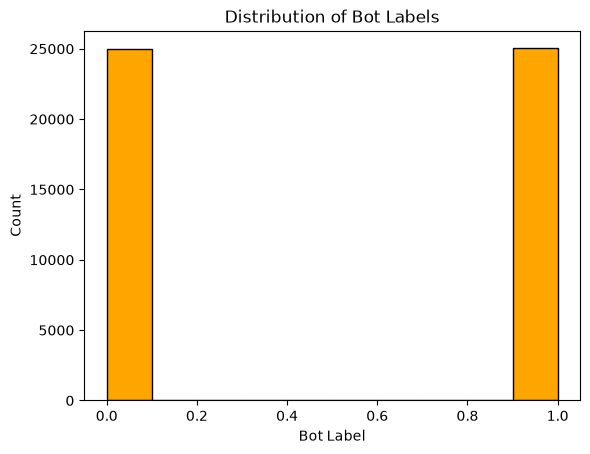

In [52]:
label = df['Bot Label']
plt.hist(label, edgecolor='black', color=['orange'])

plt.title('Distribution of Bot Labels')
plt.xlabel('Bot Label')
plt.ylabel('Count')
plt.show()

The class distribution seems well balanced.

## Correlation and Linear Independence   

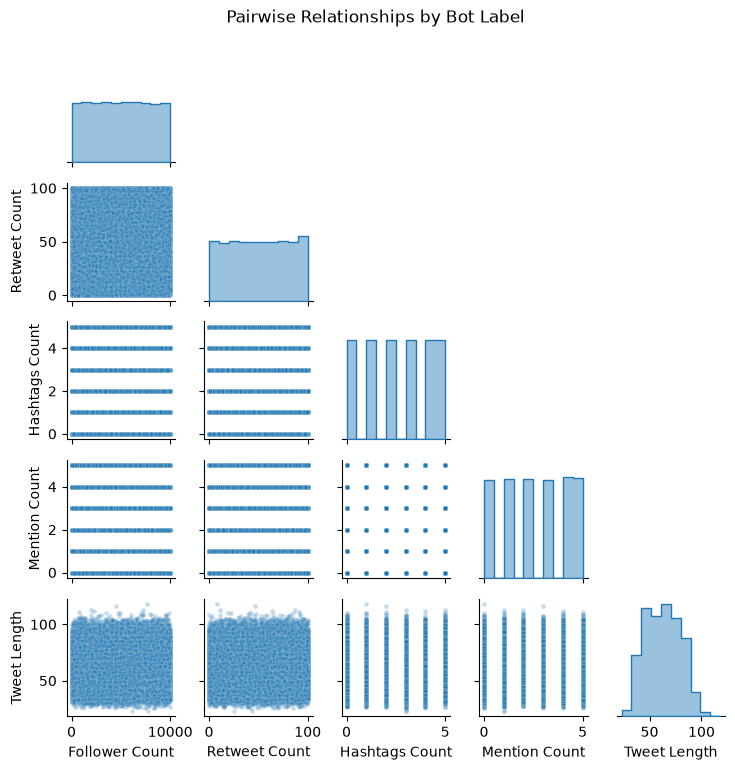

In [ ]:
numeric_cols = ['Follower Count', 'Retweet Count', 'Hashtags Count', 'Mention Count', 'Tweet Length']

grid = sns.PairGrid(
    df,
    vars=numeric_cols,
    # hue='Bot Label',
    # palette={0: 'steelblue', 1: 'darkorange'},
    corner=True,
    height=1.5
)

grid.map_lower(sns.scatterplot, alpha=0.25, s=12)
grid.map_diag(sns.histplot, bins=10, alpha=0.45, element='step')


# grid.map_upper(sns.kdeplot)
# grid.add_legend(title='Bot Label

plt.suptitle('Pairwise Relationships by Bot Label', y=1.02)
plt.show()

In [49]:
# Checkout the condition number
np.linalg.cond(df[numeric_cols].values)

np.float64(3365.2744230709095)

## Analysis of covariance in Linear features

Even though the pair plot does not suggest a direct relation between any two features in the dataset. The condition number shows strong multicollinearity among the features. 

In [53]:
# finding the specific colineatity between the features
X_numerical = df[numeric_cols].values
X_scaled = (X_numerical - np.mean(X_numerical, axis=0)) / np.std(X_numerical, axis=0)
eigenvalues, eigenvectors = np.linalg.eig(np.dot(X_scaled.T, X_scaled))

In [54]:
smallest_idx = np.argmin(eigenvalues)

In [57]:
loading_scores = pd.Series(eigenvectors[:, smallest_idx], index=numeric_cols).abs()
print(loading_scores.sort_values(ascending=False))

Follower Count    0.729734
Tweet Length      0.537636
Retweet Count     0.387867
Hashtags Count    0.166783
Mention Count     0.013314
dtype: float64


In [71]:
np.linalg.cond(df[['Retweet Count', "Tweet Length"]].values)

np.float64(3.362365011210264)

After playing around with the features, it seems that these 2 features are the only combination that resolves in a small condition number.

## Analysis of Geographic location

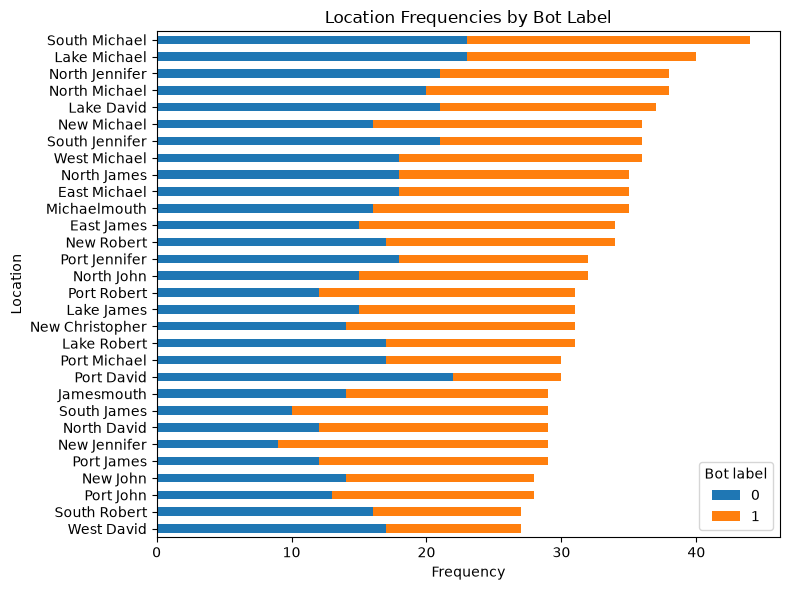

In [91]:
top_locations = df['Location'].value_counts().head(30).index

# Group by Location and Bot label
location_counts = (
    df[df['Location'].isin(top_locations)]
    .groupby(['Location', 'Bot Label'])
    .size()
    .unstack(fill_value=0)
)

# sort in decreasing order of total counts
location_counts = location_counts.loc[
    location_counts.sum(axis=1).sort_values(ascending=False).index
]


location_counts.plot(
    kind='barh',
    stacked=True,
    figsize=(8, 6),
)

plt.xlabel('Frequency')
plt.ylabel('Location')
plt.title('Location Frequencies by Bot Label')
plt.gca().invert_yaxis()
plt.legend(title='Bot label')
plt.tight_layout()
plt.show()

Again the database seems oddly balanced on this feature as well. 